# MEN 04 — Motion energy in the first 150 ms after the go cue: maps by pixel

`men_00` §9b shows bottom-camera ME rising ~12 ms after the go cue and then rippling, with peaks
near 25 and 55 ms, far faster than licking. This notebook finds where in the image that motion is
and when its peaks fall.

Method: for each go cue, the video frames from 60 ms before to 160 ms after it are cut frame-exactly
from the session's MP4 (library `video_alignment.event_frame_ranges` on the ME table's corrected
`harp_time`, then `video_clips.cut_clips`). The absolute difference between consecutive frames is
averaged over cues pixel by pixel, giving one map per 2 ms frame. Each session's clips must
reproduce the ME table's `me_clean` at a frame offset of 0 (`cue_me_maps.cue_maps`).

The clips are re-encoded (x264, `I BBB P BBB P …`), and every clip starts on the same frame type, so
clip ME carries a 4-frame (8 ms) cycle, 10–25% deep, that is the same in every clip and survives
averaging over cues. The maps are averaged over 4 consecutive frames (`cm.smooth_encoder_cycle`),
which cancels it and keeps ~91% of a 30 Hz ripple. Peak times (§1, §4) come from the ME table,
computed on the original video.

The ripples are separated from the rise with a 2nd-order Butterworth high-pass at 15 Hz, run
forwards and backwards (`cm.highpass`), so peaks keep their times. It spreads any fast rise over
about ±25 ms: before the onset its output dips although the ME does not. Only ≥ 20 ms after the cue
is read.

1. Cue-triggered ME at 500 Hz in every session: the early jump and the high-passed part, per mouse
2. Maps after the go cue, one session per mouse
3. ME by image region, and its high-passed part
4. Peak times of the high-passed ME
5. Numbers

## Setup

In [1]:
import os
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import fip_utils as fu
import men_utils as mu
import signal_utils as su
import stats_utils as st
import cue_me_maps as cm
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
IS_CO = os.path.isdir("/root/capsule")

# Same sources and cache as men_00 (the cache key must match men_00's call to be reused)
ASSET_CANDIDATES = {
    "3ch": ["/root/capsule/data/DANE_3channels_curated",
            "../../data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f"],
    "4ch": ["/root/capsule/data/DANE_4channels_curated",
            "../../data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1"],
}
ME_DATA_ROOT = "/root/capsule/data" if IS_CO else os.environ.get("ME_DATA_ROOT", "../../data")
CACHE_PATH = ("/root/capsule/scratch/men_00/sessions.pkl" if IS_CO
              else os.environ.get("MEN_CACHE", "../../data/men_00_cache/sessions.pkl"))
# Clips and per-session maps (cut once, then reused)
CLIP_DIR = "/root/capsule/scratch/men_04" if IS_CO else "../../data/men_04_cache"
FIG_DIR = "/root/capsule/scratch/figures/men" if IS_CO else "../data/figures/men"
SAVE_FIG = True

CAMERAS = ("BottomCamera", "SideCameraRight")   # men_00's cache call
CAM = "BottomCamera"
FS = 100.0                                      # men_00's grid (only for the cache key)

# ── §1: cue-triggered ME from the table, 500 Hz ──────────────────────────────
TRACE_LAGS = np.arange(-0.05, 0.15 + 1e-9, 0.002)
JUMP_WIN_MS = (10, 16)     # the early jump
HP_CUTOFF_HZ = 15.0        # high-pass (cm.highpass) separating the ripples from the rise
FAST_WIN_MS = (20, 110)    # where the high-passed part is read (it is distorted before ~20 ms)
JUMP_MIN_Z = 0.3           # mice whose mean jump exceeds this are the "early jump" group

# ── §2–3: maps ───────────────────────────────────────────────────────────────
N_CUES = 100               # go cues per session, sampled at random (seed 0)
BEFORE_S, AFTER_S = 0.06, 0.16
N_WORKERS = 3              # sessions cut in parallel
MAP_WINDOWS_MS = [(10, 16), (18, 30), (50, 62), (100, 150)]
BAND_HZ = (22, 45)         # band of the per-pixel power map

# ── §4: peaks ────────────────────────────────────────────────────────────────
PEAK_REL_PROM = 0.1        # a peak counts if its prominence is > this fraction of the range
PEAK1_MS = (20, 40)        # first peak
PEAK2_MS = (44, 70)        # second peak
SEARCH_STARTS_MS = (15, 20, 25)   # check: where the peak search starts

## 0. Data

In [3]:
asset_roots = {name: root for name, cands in ASSET_CANDIDATES.items()
               if (root := fu.find_asset_root(cands))}
me_index = fu.load_me_index(ME_DATA_ROOT)
inv = mu.inventory_sessions(asset_roots, me_index)
inv["has_trials"] = inv["path"].notna()
sessions = mu.load_sessions(inv[inv.has_trials], fs=FS, cache_path=CACHE_PATH,
                            data_root=ME_DATA_ROOT, cameras=CAMERAS)
used = set(inv.loc[inv[f"{CAM}_status"] == "ok", "ses_idx"])
sessions = [s for s in sessions if s["session"] in used]
cam_rows = me_index[(me_index.camera == CAM) & (me_index.status == "ok")].set_index("ses_idx")
print(f"{len(sessions)} sessions with a usable {CAM}, {len({s['subject'] for s in sessions})} mice")

loaded 97 sessions from cache ../../data/men_00_cache/sessions.pkl
88 sessions with a usable BottomCamera, 9 mice


## 1. Cue-triggered ME at 500 Hz in every session

The ME table's full-rate trace, z-scored over the task as in `men_00` §9b, averaged over all go cues
and separately over responded and no-response trials. Two numbers per session:

- **jump**: mean over 10–16 ms after the cue minus the mean over −50–0 ms (z);
- **fast**: SD over 20–110 ms of the high-passed trace (z).

In [4]:
DT = TRACE_LAGS[1] - TRACE_LAGS[0]
LAGS_MS = TRACE_LAGS * 1000
FAST_W = (LAGS_MS >= FAST_WIN_MS[0]) & (LAGS_MS <= FAST_WIN_MS[1])


def fast_sd(trace):
    return float(np.std(cm.highpass(trace, DT, HP_CUTOFF_HZ)[FAST_W]))


def jump(trace):
    return float(trace[(LAGS_MS >= JUMP_WIN_MS[0]) & (LAGS_MS <= JUMP_WIN_MS[1])].mean()
                 - trace[LAGS_MS < 0].mean())


rows = []
for s in sessions:
    t_me, y, _ = fu.motion_energy_to_session(s["session"], s["trials"], camera=CAM, data_root=ME_DATA_ROOT)
    fs_me = 1 / np.median(np.diff(t_me))
    z = su.zscore(y)
    tr = s["trials"]
    for cond, m in (("all", np.ones(len(tr), bool)), ("responded", tr["animal_response"] != 2),
                    ("no response", tr["animal_response"] == 2)):
        cues = tr.loc[m, "goCue_start_time_in_session"].dropna().to_numpy()
        if len(cues) < 5:
            continue
        trace = np.nanmean(su.peri_event_grid(z, t_me[0], fs_me, cues, TRACE_LAGS), axis=0)
        rows.append(dict(subject=s["subject"], session=s["session"], cond=cond, n=len(cues),
                         trace=trace, jump=jump(trace), fast=fast_sd(trace)))
cue_me = pd.DataFrame(rows)
per_mouse = (cue_me[cue_me.cond == "all"].groupby("subject")[["jump", "fast"]].mean()
             .sort_values("jump", ascending=False))
MICE = per_mouse.index.tolist()          # sorted by the early jump, largest first
JUMP_MICE = per_mouse.index[per_mouse.jump > JUMP_MIN_Z].tolist()
n_sessions = cue_me[cue_me.cond == "all"].groupby("subject").size()
print(f"early jump (> {JUMP_MIN_Z} z): {JUMP_MICE}")
per_mouse.round(2)

early jump (> 0.3 z): ['809487', '816214', '808054', '816212', '809491']


,jump,fast
subject,,
809487,1.34,0.20
816214,1.02,0.21
808054,0.93,0.18
816212,0.63,0.20
809491,0.41,0.17
818585,0.11,0.08
818586,0.04,0.06
800886,0.03,0.08
815334,-0.01,0.06


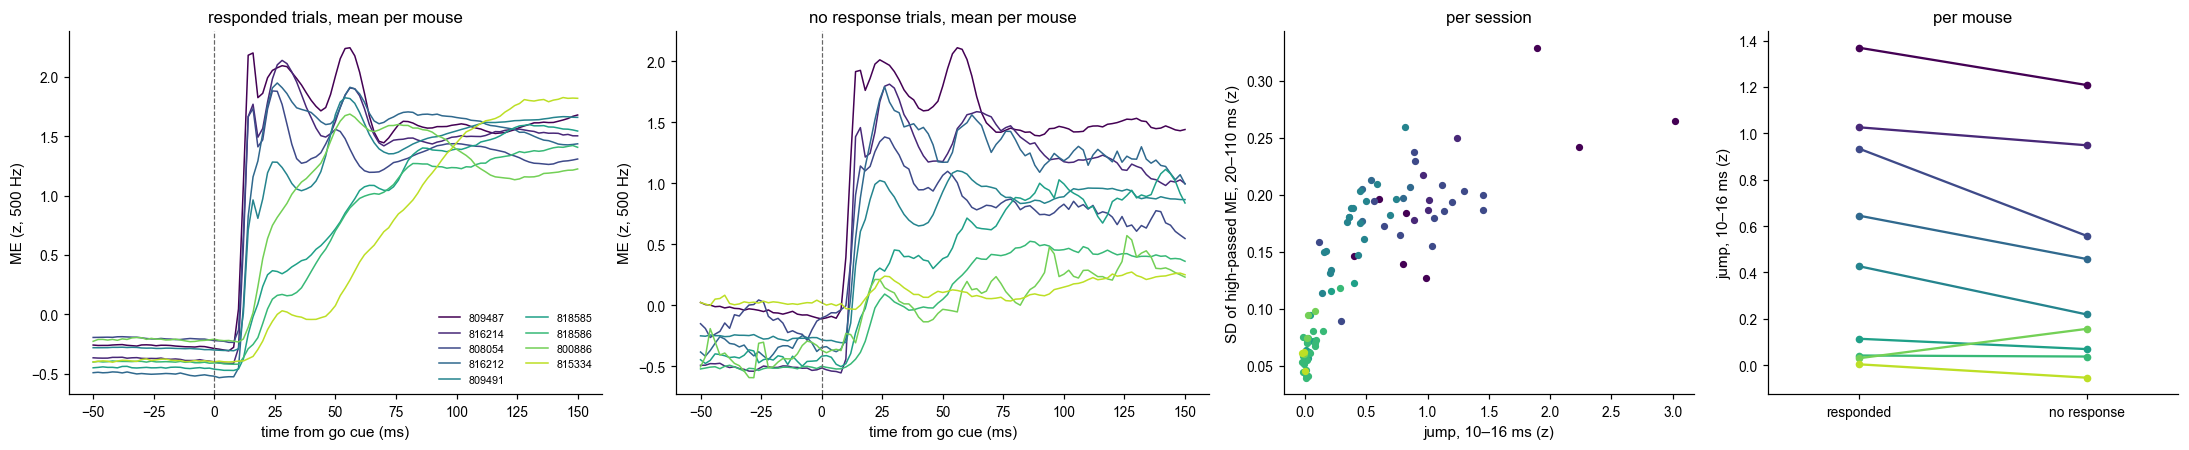

In [5]:
mouse_color = dict(zip(MICE, plt.get_cmap("viridis")(np.linspace(0, 0.9, len(MICE)))))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1.3, 1, 1]))
for ax, cond in zip(axes[:2], ("responded", "no response")):
    for mouse in MICE:
        sel = cue_me[(cue_me.cond == cond) & (cue_me.subject == mouse)]
        if len(sel):
            ax.plot(LAGS_MS, np.mean(np.stack(sel.trace), 0), color=mouse_color[mouse], lw=1, label=mouse)
    ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
    ax.set(xlabel="time from go cue (ms)", ylabel="ME (z, 500 Hz)", title=f"{cond} trials, mean per mouse")
    style_ax(ax)
axes[0].legend(fontsize=7, ncol=2)

ax = axes[2]
sel = cue_me[cue_me.cond == "all"]
for mouse in MICE:
    m = sel.subject == mouse
    ax.scatter(sel.loc[m, "jump"], sel.loc[m, "fast"], color=mouse_color[mouse], s=14)
ax.set(xlabel="jump, 10–16 ms (z)", ylabel="SD of high-passed ME, 20–110 ms (z)", title="per session")
style_ax(ax)

ax = axes[3]
paired = (cue_me[cue_me.cond != "all"].groupby(["subject", "session", "cond"])["jump"].mean()
          .groupby(["subject", "cond"]).mean().unstack("cond").reindex(MICE))
for mouse, r in paired.iterrows():
    ax.plot([0, 1], [r["responded"], r["no response"]], color=mouse_color[mouse], marker="o", ms=4)
ax.set_xticks([0, 1], ["responded", "no response"])
ax.set(xlim=(-0.4, 1.4), ylabel="jump, 10–16 ms (z)", title="per mouse")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men04_1_cue_me_500hz", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. Maps after the go cue, one session per mouse

For each mouse the session whose high-passed SD (§1) is closest to the mouse's median. Rows are
mice, largest early jump first. Columns: the mean frame with the regions of §3 filled in (dotted
lines: the region boundaries); the mean |frame difference| in four lag windows minus its mean before
the cue (one colour scale per row); and per-pixel power at 22–45 Hz of the high-passed
|difference| 20–110 ms after the cue.

The first run cuts the clips (about 5 s per cue); later runs read the cached maps.

In [6]:
pick = (cue_me[cue_me.cond == "all"].assign(
            d=lambda d: (d.fast - d.groupby("subject").fast.transform("median")).abs())
        .sort_values("d").groupby("subject").head(1).set_index("subject").reindex(MICE))
by_session = {s["session"]: s for s in sessions}


def session_maps(ses_idx):
    row = cam_rows.loc[ses_idx]
    harp, me = cm.load_frame_table(ME_DATA_ROOT, row["session"], CAM)
    cues = by_session[ses_idx]["trials"]["goCue_start_time_raw"].dropna().to_numpy()
    return cm.cue_maps(cm.video_url(row), harp, me, cues, N_CUES, BEFORE_S, AFTER_S, seed=0,
                       clip_dir=os.path.join(CLIP_DIR, "clips"), prefix=f"{ses_idx}_{CAM}",
                       cache_path=os.path.join(CLIP_DIR, f"maps_{ses_idx}_{CAM}.npz"))


with ThreadPoolExecutor(N_WORKERS) as pool:
    maps = dict(zip(MICE, pool.map(session_maps, pick["session"])))
for r in maps.values():
    r["maps"] = cm.smooth_encoder_cycle(r["maps"])
align = pd.DataFrame({mouse: dict(session=pick.loc[mouse, "session"], cues=len(r["clip_me"]),
                                  r_at_0=r["align_r"][r["align_shifts"] == 0][0],
                                  r_at_pm1=r["align_r"][np.abs(r["align_shifts"]) == 1].max())
                      for mouse, r in maps.items()}).T
align

,session,cues,r_at_0,r_at_pm1
809487,809487_2025-09-22,100,0.976535,0.930699
816214,816214_2025-12-04,100,0.990091,0.891203
808054,808054_2025-09-10,100,0.982234,0.885925
816212,816212_2025-12-11,68,0.991008,0.880853
809491,809491_2025-10-14,100,0.98114,0.93233
818585,818585_2025-12-15,100,0.98204,0.912135
818586,818586_2026-01-21,100,0.963056,0.696295
800886,800886_2025-09-03,100,0.963103,0.914442
815334,815334_2025-11-13,100,0.95634,0.934686


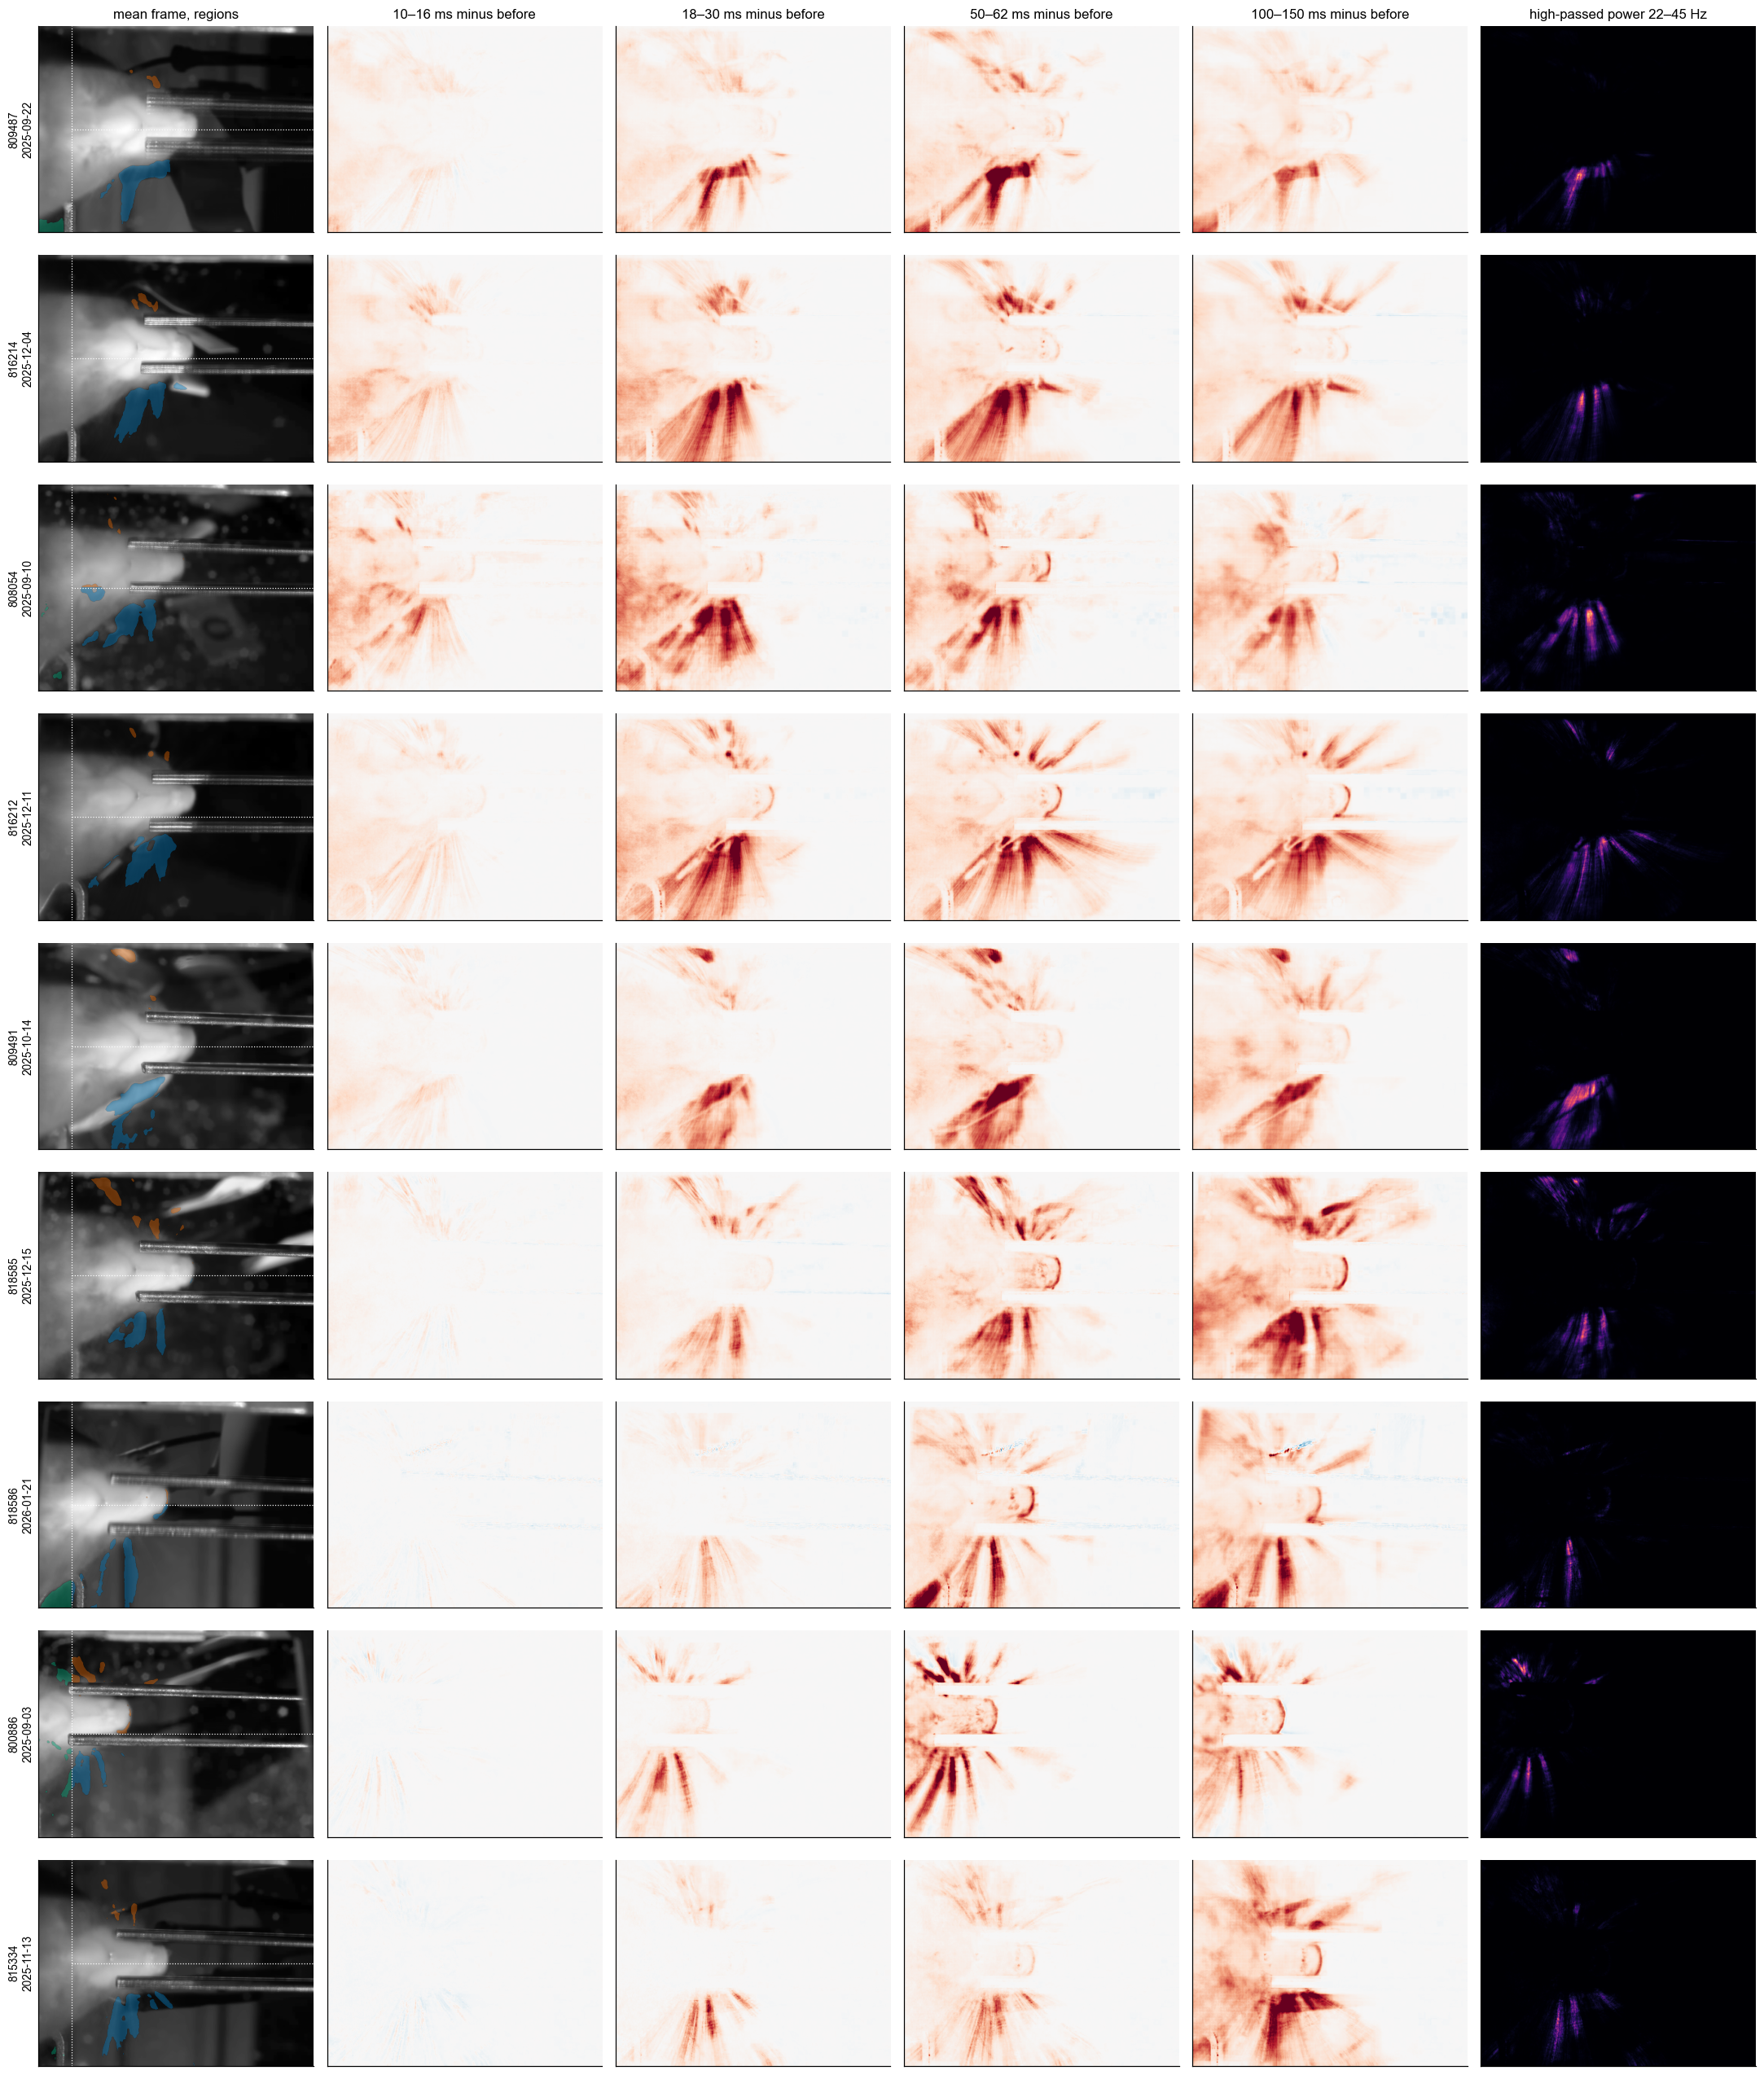

In [7]:
masks = {mouse: cm.region_masks(r["maps"], r["lags_s"]) for mouse, r in maps.items()}
n_col = 2 + len(MAP_WINDOWS_MS)
fig, axes = plt.subplots(len(MICE), n_col, figsize=(3.3 * n_col, 2.6 * len(MICE)))
for i, mouse in enumerate(MICE):
    r = maps[mouse]
    exc = cm.excess_maps(r["maps"], r["lags_s"], MAP_WINDOWS_MS)
    vmax = np.nanpercentile(np.abs(exc), 99.8)
    cm.draw_regions(axes[i, 0], r["reference"], masks[mouse])
    axes[i, 0].set_ylabel(f"{mouse}\n{pick.loc[mouse, 'session'][7:]}", fontsize=9)
    for ax, (a, b), e in zip(axes[i, 1:], MAP_WINDOWS_MS, exc):
        ax.imshow(e, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        if i == 0:
            ax.set_title(f"{a}–{b} ms minus before")
    axes[i, -1].imshow(cm.band_power_map(r["maps"], r["lags_s"], window_ms=FAST_WIN_MS, band_hz=BAND_HZ,
                                         cutoff_hz=HP_CUTOFF_HZ), cmap="magma")
    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_title("mean frame, regions")
axes[0, -1].set_title(f"high-passed power {BAND_HZ[0]}–{BAND_HZ[1]} Hz")
fig.tight_layout()
save_fig(fig, "men04_2_maps", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 3. ME by image region

Regions per session (`cm.region_masks`): the 3% of pixels with the largest mean |difference|
10–80 ms after the cue (minus before, blurred by 2 px), split at 12% of the width into the left edge
of the frame (the face and body edge) and the rest, which is split at mid-height into the upper and
lower half (mostly the whiskers on either side of the snout; in some sessions also bright objects
next to the spouts). The fourth region is every other pixel. Traces are the region's mean
|difference| minus its pre-cue mean (luma units); a region with no pixels is left out (NaN).

/Users/mib/Documents/Code/kinematics_analysis/.venv-fip/lib/python3.12/site-packages/numpy/_core/_methods.py:130: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


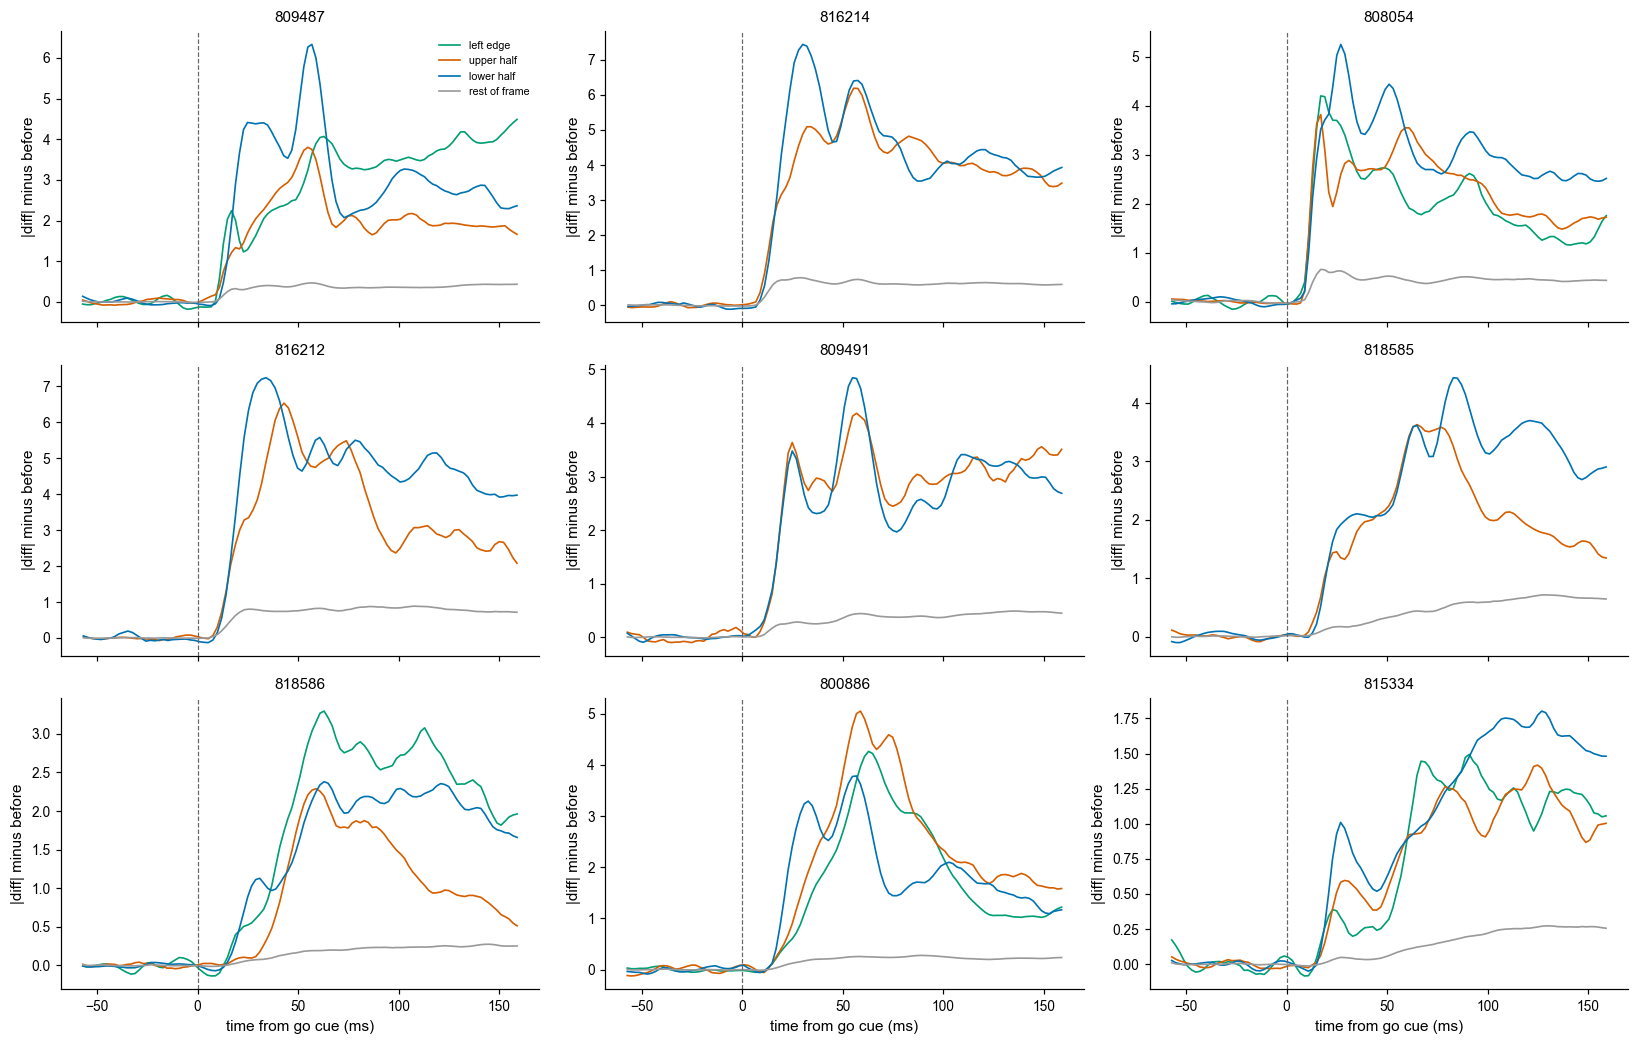

jump_frac                                     fast_frac                                    
region  left edge lower half rest of frame upper half left edge lower half rest of frame upper half
subject                                                                                            
809487       0.30       0.08          0.35       0.19      0.06       0.13          0.06       0.08
816214        NaN       0.18          0.53       0.26       NaN       0.11          0.08       0.07
808054       0.59       0.39          0.58       0.67      0.08       0.10          0.08       0.05
816212        NaN       0.12          0.30       0.15       NaN       0.10          0.07       0.08
809491        NaN       0.12          0.22       0.13       NaN       0.13          0.06       0.11
818585        NaN       0.02          0.05       0.07       NaN       0.08          0.03       0.07
818586       0.00      -0.00         -0.01       0.01      0.06       0.07          0.02       0.09
800886       0.01       0.01          0.01       0.00      0.06       0.12          0.04       0.06
815334      -0.02      -0.02         -0.03      -0.00      0.10       0.08          0.03       0.09

In [8]:
fig, axes = plt.subplots(int(np.ceil(len(MICE) / 3)), 3, figsize=(15, 3.2 * np.ceil(len(MICE) / 3)),
                         sharex=True)
region_rows, region_traces = [], {}
for ax, mouse in zip(axes.ravel(), MICE):
    r = maps[mouse]
    lags_ms = r["lags_s"] * 1000
    dt = float(np.median(np.diff(r["lags_s"])))
    w = (lags_ms >= FAST_WIN_MS[0]) & (lags_ms <= FAST_WIN_MS[1])
    for name, m in masks[mouse].items():
        trace = r["maps"][:, m].mean(1)
        trace = trace - trace[lags_ms < 0].mean()
        region_traces[(mouse, name)] = trace
        ax.plot(lags_ms, trace, color=cm.REGION_COLORS[name], lw=1.1, label=name)
        region_rows.append(dict(subject=mouse, region=name, pixels=int(m.sum()),
                                jump=trace[(lags_ms >= JUMP_WIN_MS[0]) & (lags_ms <= JUMP_WIN_MS[1])].mean(),
                                peak=trace[lags_ms > 0].max(),
                                fast=cm.highpass(trace, dt, HP_CUTOFF_HZ)[w].std() if m.any() else np.nan))
    ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
    ax.set_title(mouse, fontsize=10)
    ax.set_ylabel("|diff| minus before")
    style_ax(ax)
for ax in axes.ravel()[len(MICE):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("time from go cue (ms)")
axes.ravel()[0].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "men04_3_regions", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

regions = pd.DataFrame(region_rows)
# Jump and high-passed SD relative to the region's own peak, so regions of different size compare
regions["jump_frac"] = regions.jump / regions.peak
regions["fast_frac"] = regions.fast / regions.peak
regions.pivot(index="subject", columns="region", values=["jump_frac", "fast_frac"]).reindex(MICE).round(2)

The two whisker regions high-passed (15 Hz), with the peaks `cm.highpass_peaks` finds 20–110 ms
after the cue (prominence > 10% of the range). Grey: before 20 ms, where the filter's spread of the
onset dominates.

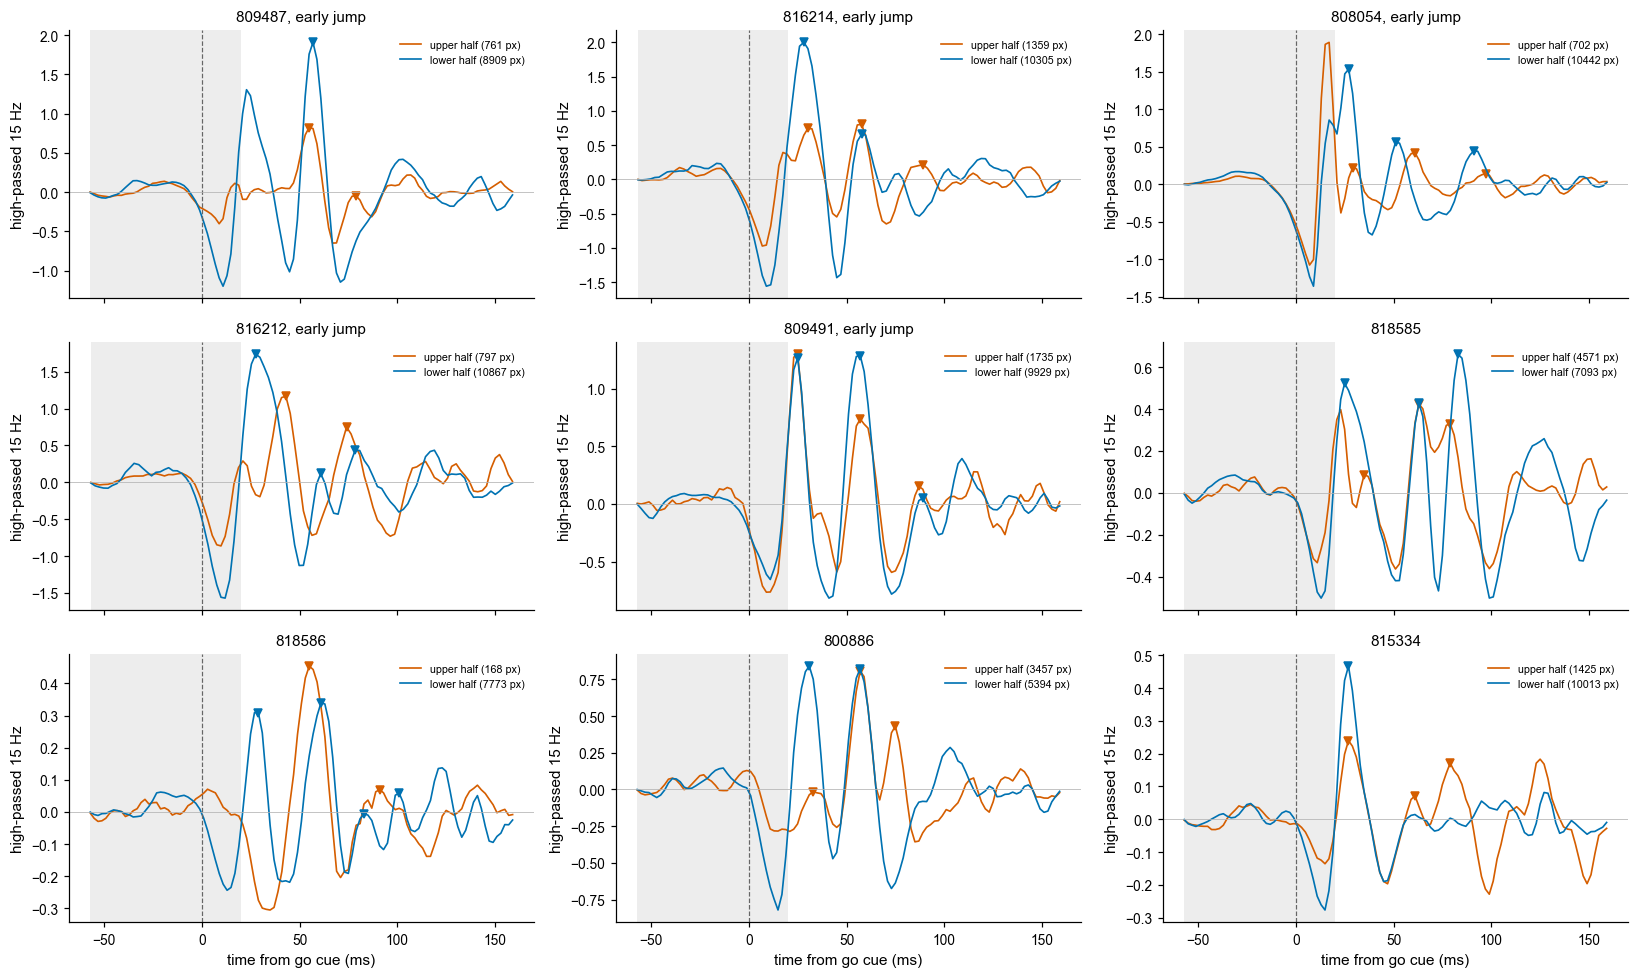

In [9]:
WHISKERS = ("upper half", "lower half")
fig, axes = plt.subplots(int(np.ceil(len(MICE) / 3)), 3, figsize=(15, 3.0 * np.ceil(len(MICE) / 3)),
                         sharex=True)
region_peak_rows = []
for ax, mouse in zip(axes.ravel(), MICE):
    r = maps[mouse]
    lags_ms = r["lags_s"] * 1000
    dt = float(np.median(np.diff(r["lags_s"])))
    for name in WHISKERS:
        if not masks[mouse][name].any():
            continue
        trace = region_traces[(mouse, name)]
        hp = cm.highpass(trace, dt, HP_CUTOFF_HZ)
        times, prom = cm.highpass_peaks(r["lags_s"], trace, HP_CUTOFF_HZ, FAST_WIN_MS, PEAK_REL_PROM)
        col = cm.REGION_COLORS[name]
        ax.plot(lags_ms, hp, color=col, lw=1.1, label=f"{name} ({masks[mouse][name].sum()} px)")
        ax.plot(times, hp[np.searchsorted(lags_ms, times)], "v", color=col, ms=5)
        region_peak_rows += [dict(subject=mouse, source=f"clips, {name}", t=t, prom=p)
                             for t, p in zip(times, prom)]
    ax.axvspan(lags_ms[0], FAST_WIN_MS[0], color="0.93", lw=0, zorder=0)
    ax.axvline(0, color=PALETTE["neutral"], ls="--", lw=0.8)
    ax.axhline(0, color="0.7", lw=0.5)
    ax.set_title(f"{mouse}" + (", early jump" if mouse in JUMP_MICE else ""), fontsize=10)
    ax.set_ylabel(f"high-passed {HP_CUTOFF_HZ:.0f} Hz")
    ax.legend(fontsize=7, loc="upper right")
    style_ax(ax)
for ax in axes.ravel()[len(MICE):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("time from go cue (ms)")
fig.tight_layout()
save_fig(fig, "men04_3b_whiskers_highpass", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 4. Peak times of the high-passed ME

Peaks of the high-passed ME table traces (original video, all cues of a session), per session and
for each mouse's mean of its sessions, next to the whisker-region peaks from the clips (§3).

- **a** peaks per session in 4 ms bins, mice with and without the early jump;
- **b** per mouse: single sessions (grey), the mouse mean (black) and the whisker regions (▲ upper,
  ▼ lower); marker size is prominence / range;
- **c** the first (20–40 ms) and second (44–70 ms) peak of every session.

A check follows: the peak search starting at 15, 20 or 25 ms. The first peak sits just after the
start of the search, and in mice without the jump it coincides with the start of the movement, which
the high-pass turns into a peak of its own.

In [10]:
ses_peak_rows, mouse_peak_rows = [], []
for mouse in MICE:
    sel = cue_me[(cue_me.cond == "all") & (cue_me.subject == mouse)]
    for session, trace in zip(sel.session, sel.trace):
        times, prom = cm.highpass_peaks(TRACE_LAGS, trace, HP_CUTOFF_HZ, FAST_WIN_MS, PEAK_REL_PROM)
        ses_peak_rows += [dict(subject=mouse, session=session, t=t, prom=p) for t, p in zip(times, prom)]
    times, prom = cm.highpass_peaks(TRACE_LAGS, np.mean(np.stack(sel.trace), 0), HP_CUTOFF_HZ,
                                    FAST_WIN_MS, PEAK_REL_PROM)
    mouse_peak_rows += [dict(subject=mouse, source="ME table, mouse mean", t=t, prom=p)
                        for t, p in zip(times, prom)]
ses_peaks = pd.DataFrame(ses_peak_rows)
mouse_peaks = pd.concat([pd.DataFrame(mouse_peak_rows), pd.DataFrame(region_peak_rows)], ignore_index=True)


def first_second(peaks_df):
    # First and second peak per session (NaN when the session has none in the window)
    g = peaks_df.groupby(["subject", "session"]).t
    p1 = g.apply(lambda t: t[(t >= PEAK1_MS[0]) & (t < PEAK1_MS[1])].min())
    p2 = g.apply(lambda t: t[(t >= PEAK2_MS[0]) & (t <= PEAK2_MS[1])].min())
    out = pd.DataFrame({"p1": p1, "p2": p2})
    every = cue_me[cue_me.cond == "all"].set_index(["subject", "session"]).index
    return out.reindex(every).reset_index()


per_session = first_second(ses_peaks)
per_session["group"] = np.where(per_session.subject.isin(JUMP_MICE), "early jump", "no jump")
peak_summary = per_session.groupby("subject").agg(
    sessions=("p1", "size"), p1_ms=("p1", "median"), p1_found=("p1", lambda v: v.notna().mean()),
    p2_ms=("p2", "median"), p2_found=("p2", lambda v: v.notna().mean())).reindex(MICE)
peak_summary.round(2)

,sessions,p1_ms,p1_found,p2_ms,p2_found
subject,,,,,
809487,8,22.0,0.12,56.0,1.0
816214,5,26.0,1.00,58.0,1.0
808054,15,24.0,1.00,50.0,1.0
816212,5,24.0,0.80,58.0,1.0
809491,19,23.0,0.84,54.0,1.0
818585,7,22.0,0.86,60.0,1.0
818586,22,24.0,1.00,55.0,1.0
800886,4,27.0,1.00,54.0,1.0
815334,3,28.0,1.00,62.0,1.0


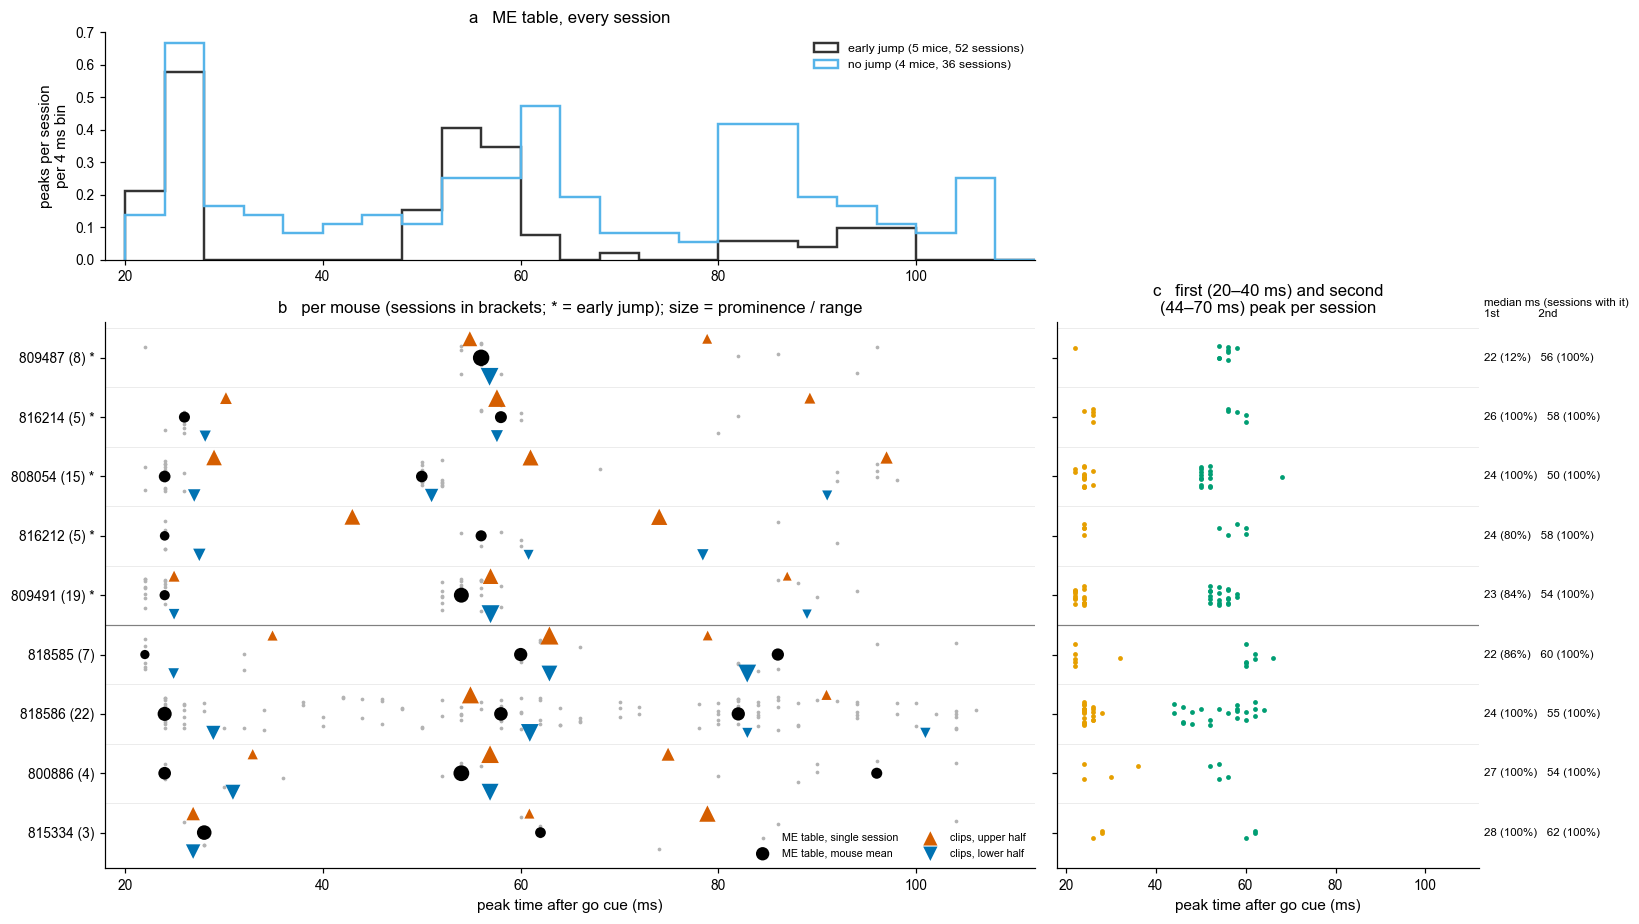

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), gridspec_kw=dict(height_ratios=[1, 2.4], width_ratios=[2.2, 1]))
ypos = {m: len(MICE) - 1 - k for k, m in enumerate(MICE)}
rng = np.random.default_rng(0)
xlim = (FAST_WIN_MS[0] - 2, FAST_WIN_MS[1] + 2)

ax = axes[0, 0]
bins = np.arange(FAST_WIN_MS[0], FAST_WIN_MS[1] + 4, 4)
for group, color in (("early jump", "#333333"), ("no jump", OKABE_ITO["sky_blue"])):
    mice = JUMP_MICE if group == "early jump" else [m for m in MICE if m not in JUMP_MICE]
    s = ses_peaks[ses_peaks.subject.isin(mice)]
    n = n_sessions[mice].sum()
    ax.hist(s.t, bins=bins, weights=np.full(len(s), 1 / n), histtype="step", lw=1.6, color=color,
            label=f"{group} ({len(mice)} mice, {n} sessions)")
ax.set(ylabel="peaks per session\nper 4 ms bin", xlim=xlim, title="a   ME table, every session")
ax.legend(fontsize=8)
style_ax(ax)

ax = axes[1, 0]
ax.scatter(ses_peaks.t, ses_peaks.subject.map(ypos) + rng.uniform(-0.28, 0.28, len(ses_peaks)), s=6,
           color="0.7", lw=0, label="ME table, single session")
marker = {"ME table, mouse mean": ("o", "k", 0), "clips, upper half": ("^", cm.REGION_COLORS["upper half"], 0.32),
          "clips, lower half": ("v", cm.REGION_COLORS["lower half"], -0.32)}
for source, (mk, color, off) in marker.items():
    s = mouse_peaks[mouse_peaks.source == source]
    ax.scatter(s.t, s.subject.map(ypos) + off, s=20 + 120 * s.prom, marker=mk, color=color,
               edgecolor="none", label=source)
ax.set_yticks(list(ypos.values()), [f"{m} ({n_sessions[m]})" + (" *" if m in JUMP_MICE else "") for m in ypos])
for k in range(len(MICE)):
    ax.axhline(k + 0.5, color="0.92", lw=0.6)
ax.axhline(len(MICE) - len(JUMP_MICE) - 0.5, color="0.5", lw=0.8)
ax.set(xlabel="peak time after go cue (ms)", xlim=xlim, ylim=(-0.6, len(MICE) - 0.4),
       title="b   per mouse (sessions in brackets; * = early jump); size = prominence / range")
ax.legend(fontsize=7, loc="lower right", ncol=2)
style_ax(ax)

axes[0, 1].axis("off")
ax = axes[1, 1]
for mouse in MICE:
    s = per_session[per_session.subject == mouse]
    jit = rng.uniform(-0.2, 0.2, len(s))
    ax.scatter(s.p1, ypos[mouse] + jit, s=10, color=OKABE_ITO["orange"], lw=0)
    ax.scatter(s.p2, ypos[mouse] + jit, s=10, color=OKABE_ITO["bluish_green"], lw=0)
    r = peak_summary.loc[mouse]
    ax.text(xlim[1] + 1, ypos[mouse], f"{r.p1_ms:.0f} ({r.p1_found:.0%})   {r.p2_ms:.0f} ({r.p2_found:.0%})",
            va="center", fontsize=7.5)
ax.text(xlim[1] + 1, len(MICE) - 0.35, "median ms (sessions with it)\n1st            2nd", fontsize=7.5, va="bottom")
ax.set_yticks(list(ypos.values()), [""] * len(ypos))
for k in range(len(MICE)):
    ax.axhline(k + 0.5, color="0.92", lw=0.6)
ax.axhline(len(MICE) - len(JUMP_MICE) - 0.5, color="0.5", lw=0.8)
ax.set(xlim=xlim, ylim=(-0.6, len(MICE) - 0.4), xlabel="peak time after go cue (ms)",
       title=f"c   first ({PEAK1_MS[0]}–{PEAK1_MS[1]} ms) and second\n({PEAK2_MS[0]}–{PEAK2_MS[1]} ms) peak per session")
style_ax(ax)
fig.tight_layout()
save_fig(fig, "men04_4_peak_times", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

In [12]:
# Check: where the peak search starts
rows = []
for start in SEARCH_STARTS_MS:
    pk = []
    for mouse in MICE:
        sel = cue_me[(cue_me.cond == "all") & (cue_me.subject == mouse)]
        for session, trace in zip(sel.session, sel.trace):
            times, _ = cm.highpass_peaks(TRACE_LAGS, trace, HP_CUTOFF_HZ, (start, FAST_WIN_MS[1]), PEAK_REL_PROM)
            pk += [dict(subject=mouse, session=session, t=t) for t in times]
    fs_ = first_second(pd.DataFrame(pk)) if pk else per_session.iloc[:0]
    fs_["group"] = np.where(fs_.subject.isin(JUMP_MICE), "early jump", "no jump")
    for group, g in fs_.groupby("group"):
        rows.append(dict(search_from_ms=start, group=group, sessions=len(g),
                         p1_ms=g.p1.median(), p1_found=g.p1.notna().mean(),
                         p2_ms=g.p2.median(), p2_found=g.p2.notna().mean(),
                         interval_ms=(g.p2 - g.p1).median()))
search_check = pd.DataFrame(rows).set_index(["search_from_ms", "group"])
search_check.round(2)

sessions  p1_ms  p1_found  p2_ms  p2_found  interval_ms
search_from_ms group                                                              
15             early jump        52   24.0      0.83   54.0       1.0         30.0
               no jump           36   24.0      0.97   58.0       1.0         34.0
20             early jump        52   24.0      0.79   54.0       1.0         30.0
               no jump           36   24.0      0.97   58.0       1.0         34.0
25             early jump        52    NaN      0.00   54.0       1.0          NaN
               no jump           36   32.0      0.28   57.0       1.0         16.0

## 5. Numbers

In [13]:
print(f"§1  {len(cue_me[cue_me.cond == 'all'])} sessions, {len(MICE)} mice; per-mouse jump 10–16 ms "
      f"{per_mouse.jump.min():.2f}–{per_mouse.jump.max():.2f} z; early jump (> {JUMP_MIN_Z} z) in "
      f"{len(JUMP_MICE)}: {', '.join(map(str, JUMP_MICE))}")
d = paired["responded"] - paired["no response"]
m, p, n = st.wilcoxon_animals(d)
print(f"§1  jump, responded − no response: {m:+.2f} z (Wilcoxon p = {p:.3g}, n = {n} mice)")
print(f"§2  clips match the ME table at offset 0 in every session: r {align.r_at_0.min():.3f}–"
      f"{align.r_at_0.max():.3f} (±1 frame at most {align.r_at_pm1.max():.3f})")
for group, g in per_session.groupby("group"):
    print(f"§4  {group}: {len(g)} sessions; 1st peak median {g.p1.median():.0f} ms (in {g.p1.notna().mean():.0%}), "
          f"2nd {g.p2.median():.0f} ms (in {g.p2.notna().mean():.0%}), interval {(g.p2 - g.p1).median():.0f} ms")
print(f"§4  2nd peak per mouse (median over sessions): {peak_summary.p2_ms.min():.0f}–{peak_summary.p2_ms.max():.0f} ms, "
      f"found in {peak_summary.p2_found.min():.0%}–{peak_summary.p2_found.max():.0%} of each mouse's sessions")

§1  88 sessions, 9 mice; per-mouse jump 10–16 ms -0.01–1.34 z; early jump (> 0.3 z) in 5: 809487, 816214, 808054, 816212, 809491
§1  jump, responded − no response: +0.11 z (Wilcoxon p = 0.0391, n = 9 mice)
§2  clips match the ME table at offset 0 in every session: r 0.956–0.991 (±1 frame at most 0.935)
§4  early jump: 52 sessions; 1st peak median 24 ms (in 79%), 2nd 54 ms (in 100%), interval 30 ms
§4  no jump: 36 sessions; 1st peak median 24 ms (in 97%), 2nd 58 ms (in 100%), interval 34 ms
§4  2nd peak per mouse (median over sessions): 50–62 ms, found in 100%–100% of each mouse's sessions
